# 品类与价格带分析

商品卖什么、卖什么价位：品类销售额 TOP10 与价格带分布。

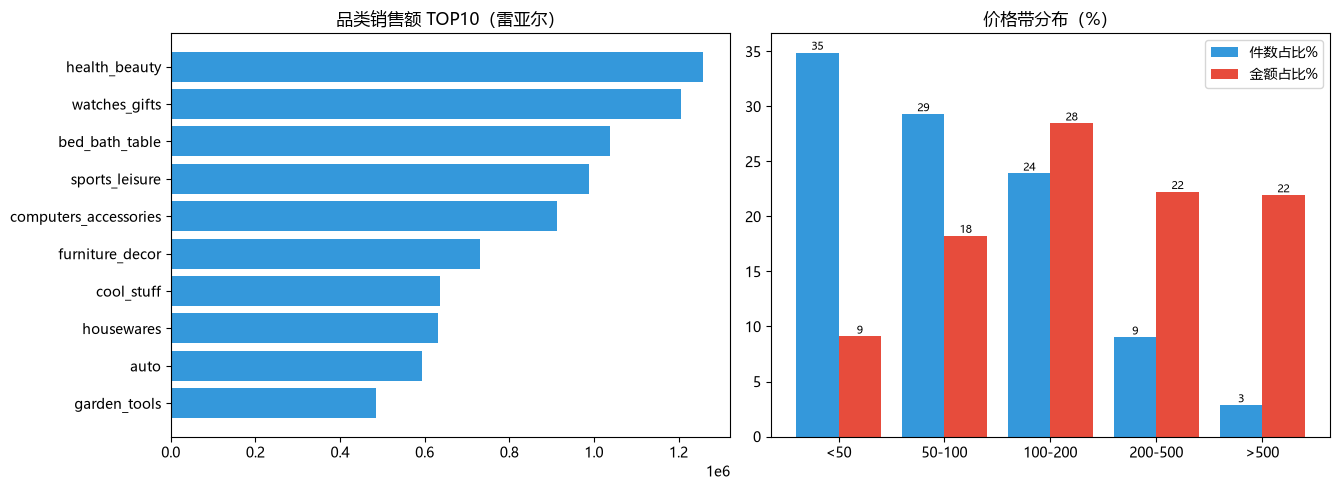

                                  件数        销售额     均价
product_category_name_english                         
health_beauty                   9670  1258681.3  130.2
watches_gifts                   5991  1205005.7  201.1
bed_bath_table                 11115  1036988.7   93.3
sports_leisure                  8641   988049.0  114.3
computers_accessories           7827   911954.3  116.5
furniture_decor                 8334   729762.5   87.6
cool_stuff                      3796   635290.8  167.4
housewares                      6964   632248.7   90.8
auto                            4235   592720.1  140.0
garden_tools                    4347   485256.5  111.6


In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

items = pd.read_csv('data/order_items_clean.csv')
products = pd.read_csv('data/products_clean.csv')
it = items.merge(products[['product_id', 'product_category_name_english']], on='product_id')

cat = it.groupby('product_category_name_english').agg(
    件数=('price', 'size'), 销售额=('price', 'sum'), 均价=('price', 'mean'))
top10 = cat.sort_values('销售额', ascending=False).head(10)

bands = pd.cut(it['price'], [0, 50, 100, 200, 500, 1e9],
               labels=['<50', '50-100', '100-200', '200-500', '>500'])
b = it.groupby(bands, observed=True)['price'].agg(['size', 'sum'])
b['件数占比%'] = b['size'] / b['size'].sum() * 100
b['金额占比%'] = b['sum'] / b['sum'].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))
axes[0].barh(top10.index[::-1], top10['销售额'][::-1], color='#3498db')
axes[0].set_title('品类销售额 TOP10（雷亚尔）')

xx = np.arange(5)
axes[1].bar(xx - .2, b['件数占比%'], .4, label='件数占比%', color='#3498db')
axes[1].bar(xx + .2, b['金额占比%'], .4, label='金额占比%', color='#e74c3c')
axes[1].set_xticks(xx, b.index); axes[1].set_title('价格带分布（%）'); axes[1].legend()
for i, (a, c) in enumerate(zip(b['件数占比%'], b['金额占比%'])):
    axes[1].text(i - .2, a, f'{a:.0f}', ha='center', va='bottom', fontsize=8)
    axes[1].text(i + .2, c, f'{c:.0f}', ha='center', va='bottom', fontsize=8)
plt.tight_layout(); plt.show()
print(top10.round(1).to_string())


## 结论

- **头部品类**：健康美容（126 万）、手表礼品（121 万）、床品餐桌（104 万）为销售额前三；手表礼品均价最高（201 雷亚尔），是平台的高客单价品类。
- **低价格带走量、高价格带拉金额**：<50 价位占 34.9% 件数但仅 9.1% 金额；100–200 价位贡献最大金额占比（28.5%）；>500 仅 2.9% 件数却贡献 21.9% 金额。
- **运营含义**：货盘主力在 100 雷亚尔上下，"中低价高频走量 + 少量高价拉升金额"是平台的基本盘。

## 业务解读

- 健康美容（126 万）、手表礼品（121 万）是销售额与客单价双高的「利润引擎」品类；床品餐桌（104 万）是「流量品类」——件数最多但均价 93。
- 价格带呈纺锤形：<50 走量引流（34.9% 件数、9.1% 金额），100–200 是主力价格带（28.5% 金额），>500 贡献 21.9% 金额但仅 2.9% 件数。
- >500 价位的存在说明平台已有中高端消费力，值得扩充高价位货盘（手表、家电、电脑）。
- 与支付分析联动：高价商品必须支持长分期（12 期以上），否则 200+ 价位转化会受信贷约束压制。

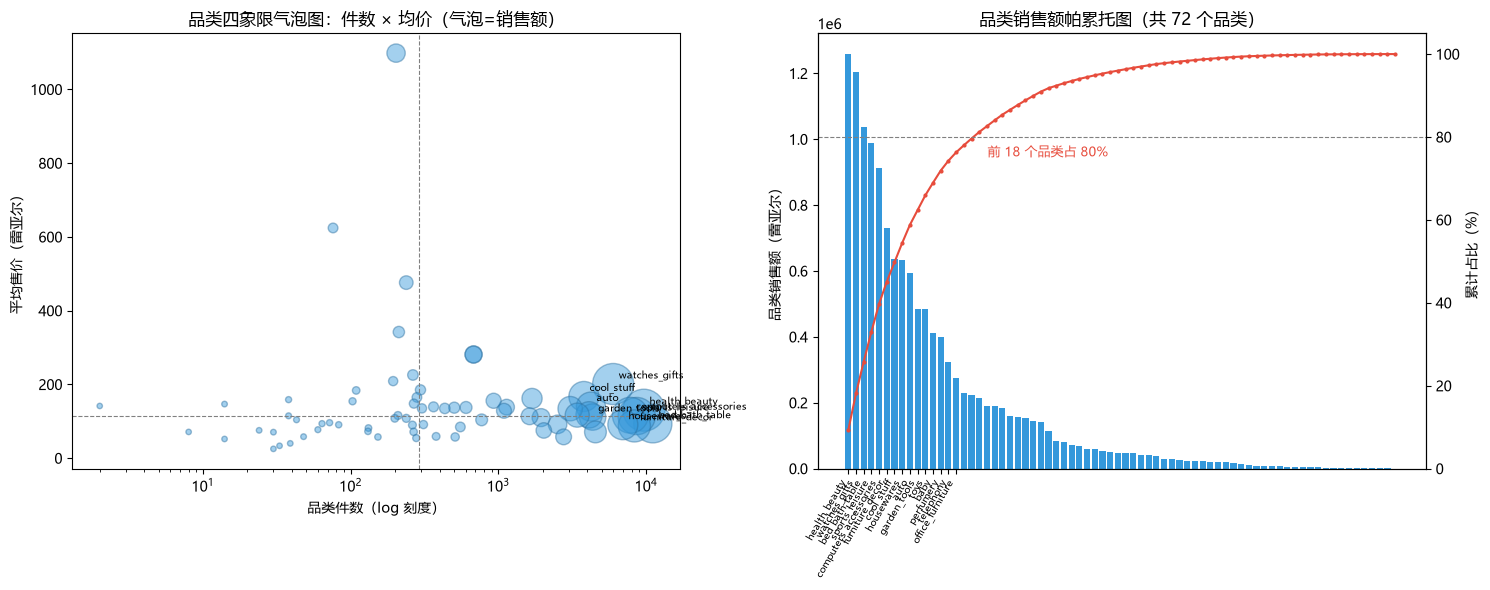

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ① 品类四象限气泡图：x=件数(log)，y=均价，气泡=销售额，标注 TOP10
cat_s = cat.sort_values('销售额', ascending=False)
axes[0].scatter(cat_s['件数'], cat_s['均价'],
                s=cat_s['销售额'] / cat_s['销售额'].max() * 900 + 15,
                alpha=.45, color='#3498db', edgecolor='#2c6f9e')
axes[0].set_xscale('log')
axes[0].axvline(cat_s['件数'].median(), color='gray', ls='--', lw=.8)
axes[0].axhline(cat_s['均价'].median(), color='gray', ls='--', lw=.8)
for name_, row in cat_s.head(10).iterrows():
    axes[0].annotate(name_, (row['件数'], row['均价']), fontsize=7.5,
                     textcoords='offset points', xytext=(4, 4))
axes[0].set_xlabel('品类件数（log 刻度）'); axes[0].set_ylabel('平均售价（雷亚尔）')
axes[0].set_title('品类四象限气泡图：件数 × 均价（气泡=销售额）')

# ② 品类销售额帕累托图：降序柱 + 累计占比折线
cs = cat['销售额'].sort_values(ascending=False)
cum = cs.cumsum() / cs.sum() * 100
axes[1].bar(range(len(cs)), cs.values, color='#3498db')
ax2 = axes[1].twinx()
ax2.plot(range(len(cs)), cum.values, color='#e74c3c', marker='.', ms=4)
ax2.axhline(80, color='gray', ls='--', lw=.8)
ax2.set_ylabel('累计占比（%）'); ax2.set_ylim(0, 105)
n80 = int((cum <= 80).sum()) + 1
ax2.annotate(f'前 {n80} 个品类占 80%', (n80 - 1, 80), textcoords='offset points',
             xytext=(6, -14), fontsize=9, color='#e74c3c')
axes[1].set_xticks(range(15), cs.index[:15], rotation=60, ha='right', fontsize=7)
axes[1].set_ylabel('品类销售额（雷亚尔）')
axes[1].set_title(f'品类销售额帕累托图（共 {len(cs)} 个品类）')

plt.tight_layout()
plt.show()